### **Supervised Learning**

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [84]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint
import optuna
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    ParameterGrid
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    r2_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor
)
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif, RFE, RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.datasets import load_iris, load_breast_cancer

from xgboost import XGBRegressor, XGBClassifier

### სხვადასხვა მოდელების შედარება

In [3]:
# iris dataset ჩავტვირთვა
iris = load_iris()
df_iris = pd.DataFrame(data=iris["data"], columns=iris["feature_names"])
df_iris["species"] = iris["target"]
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [8]:
# features and target
X, y = df_iris[["petal length (cm)", "petal width (cm)"]], iris["target"]

# დავყოთ მონაცემები Training and Testing Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

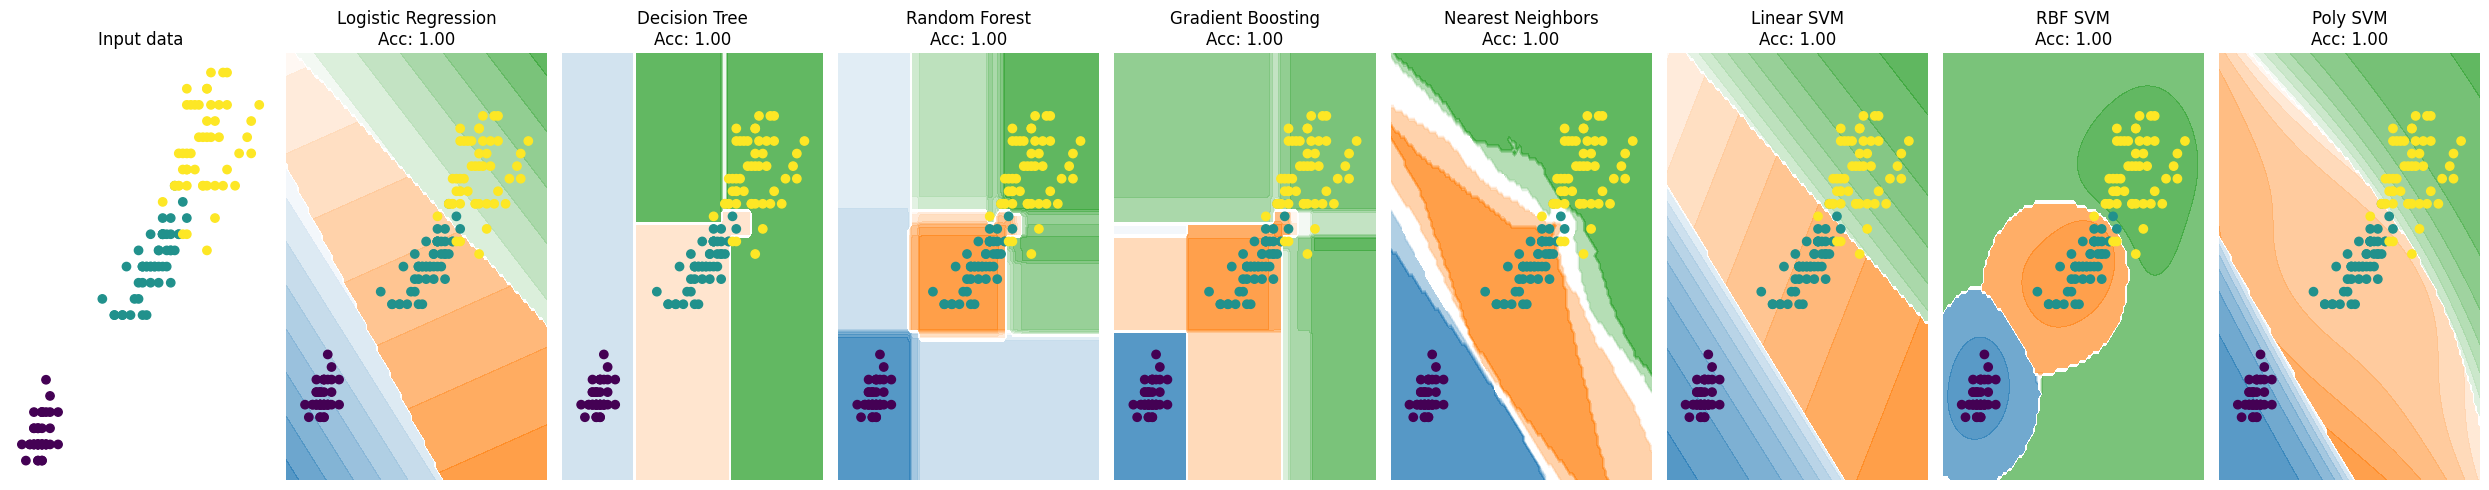

In [9]:
# გავწვრთნათ სხვადასხვა მოდელი
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Linear SVM": SVC(kernel="linear", C=0.025, random_state=42),
    "RBF SVM": SVC(kernel="rbf", gamma=2, C=1, random_state=42),
    "Poly SVM": SVC(kernel="poly", degree=3, C=1, gamma="scale", random_state=42),
}

# Plot Setup
figure = plt.figure(figsize=(25, 5))
plt.subplot(1, len(models) + 1, 1)
plt.scatter(X["petal length (cm)"], X["petal width (cm)"], c=y)
plt.title("Input data")
plt.axis("off")

for i, (name, clf) in enumerate(models.items()):
    pipeline = make_pipeline(StandardScaler(), clf) # make_pipeline აერთიანებს რამდენიმე ნაბიჯს
    pipeline.fit(X_train, y_train)
    score = pipeline.score(X_test, y_test)

    ax = plt.subplot(1, len(models) + 1, i + 2)
    DecisionBoundaryDisplay.from_estimator(pipeline, X, cmap=plt.cm.RdBu, alpha=0.8, ax=ax, eps=0.5)
    plt.scatter(X["petal length (cm)"], X["petal width (cm)"], c=y)
    plt.title(f"{name}\nAcc: {score:.2f}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## ჰიპერპარამეტრების ოპტიმიზაცია
ჩვენი მიზანია ვიპოვოთ ჰიპერპარამეტრების ისეთი კომბინაციია, რომელიც უზრუნველყოფს საუკეთესო შედეგს.
ისე რომ, მოდელს ჰქონდეს მინიმალური შეცდომა, მაქსიმალური სიზუსტე.

---

* არასწორი ჰიპერპარამეტრები → underfitting ან overfitting
* ოპტიმალური ჰიპერპარამეტრები → უკეთესი შედეგები


მეთოდები ჰიპერპარამეტრების ოპტიმიზაციისთვის:

| მეთოდი                             | აღწერა                                                         | უპირატესობა                  | უარყოფითი მხარე                      | რეკომენდირებულია როცა გვაქვს|
| ---------------------------------- | -------------------------------------------------------------- | ---------------------------- | ------------------------------------ |---------------------------------- |
| **Grid Search**                    | ყველა შესაძლო კომბინაციას სინჯავს (brute-force)                             | მარტივი           | ნელი          | მცირე რაოდენობის პარამეტრები | 
| **Random Search**                  | შემთხვევით სინჯავს პარამეტრების კომბინაციებს                   | უფრო სწრაფი დიდ სივრცეში     | შეიძლება გამორჩეს კარგი კომბინაციები | ბევრი პარამეტრი              | 
| **Bayesian Optimization / Optuna** | სწავლობს, რომელი პარამეტრებია ეფექტური | ეფექტური           | უფრო რთული რეალიზაცია                | დრო/რესურსის შეზღუდვა        |

---

<img src="../../images/hyperparameters.webp" width="800">

## ზოგადი ნაბიჯები
1. მოდელის შერჩევა (მაგალითად `RandomForestClassifier`)
2. პარამეტრების შერჩევა (`n_estimators` 100-800)
3. ოპტიმიზაციის მეთოდის შერჩევა (Grid, Random, Optuna)
4. cross_validation (მაგ. 5-Fold CV)
5. საბოლოო შედეგების გადამოწმება validation და შემდეგ test სიმრავლეებზე

---

| მოდელი        | ჰიპერპარამეტრები                             |
| ------------- | -------------------------------------------- |
| Random Forest | `n_estimators`, `max_depth`, `max_features`  |
| SVM           | `C`, `gamma`, `kernel`                       |
| k-NN          | `n_neighbors`, `metric`                      |
| XGBoost       | `learning_rate`, `max_depth`, `n_estimators` |
---

მაგალითი: SVM `C` და `gamma`

| მეთოდი                             | მაგალითი (SVM - `C`, `gamma`)                                   | მოდელის გამოძახება                                 |
| ---------------------------------- | ---------------------------------------------------------------- | -------------------------------------------------- |
| **Grid Search**                    | `C`: [0.1, 1, 10] × `gamma`: [0.01, 0.1, 1, 10] → 3×4 = 12 კომბინაცია | `SVC(C=1, gamma=0.1)`                             |
| **Random Search**                  | `C` ∈ [0.01, 100], `gamma` ∈ [0.001, 10] → 20 შემთხვევითი კომბინაცია | `SVC(C=23.7, gamma=0.005)`                         |
| **Bayesian Optimization / Optuna** | Optuna ირჩევს `C`, `gamma` არსებული შედეგების ანალიზით            | `SVC(C=5.2, gamma=0.12)`|
| **ხელით არჩევა**                   | სცადე ხელით: `C=1`, `gamma=0.1`; შემდეგ `C=10`, `gamma=0.01`      | `SVC(C=1, gamma=0.1)`                            |

---

### Wine Quality Dataset

In [10]:
# მონაცემების ჩატვირთვა
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df_wine = pd.read_csv(url, sep=";")
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [11]:
df_wine["quality"].value_counts().sort_index().reset_index()

,quality,count
0,3,10
1,4,53
2,5,681
3,6,638
4,7,199
5,8,18


|Quality | Class|
|--------|-------|
|3-5 | 0 (bad wine)|
|6-8 | 1 (good wine)|

In [12]:
df_wine["quality"] = (df_wine["quality"] >= 6).astype(int)

In [13]:
# მახასიათებლების (X) და სამიზნის (y) გამოყოფა
X = df_wine.drop("quality", axis=1)
y = df_wine["quality"]

# მონაცემთა გაყოფა სასწავლო (80%) და სატესტო (20%) ნაწილებად
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
# მოდელის გაწვრთნა
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [15]:
# პროგნოზი
y_pred = model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

Test Accuracy: 0.790625


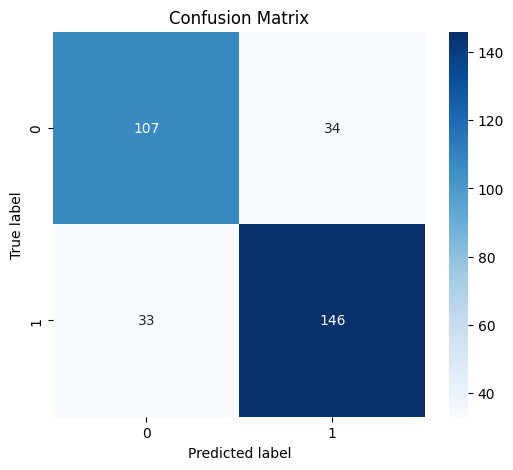

In [16]:
# confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=model.classes_, yticklabels=model.classes_)
plt.title("Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()

In [17]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [18]:
# მონაცემთა გაყოფა სასწავლო (60%), სატესტო (20%), ვალიდაციის (20%) ნაწილებად
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)  # 0.25 * 0.8 = 0.2

In [19]:
# განვსაზღვროთ param grid
param_grid = {
    "n_estimators": [100, 150, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
}

# ჰიპერპარამეტრების კომბინაცია
grid = list(ParameterGrid(param_grid))
grid

[{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100},
 {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 150},
 {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200},
 {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100},
 {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 150},
 {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200},
 {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100},
 {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 150},
 {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200},
 {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100},
 {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 150},
 {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200},
 {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100},
 {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150},
 {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200},
 {'max_depth'

თუ 
params = {
    n_estimators=150,
    max_depth=10,
    min_samples_split=2
}

RandomForestClassifier(**params, random_state=42) იგივეა, რაც

RandomForestClassifier(
    n_estimators=150,
    max_depth=10,
    min_samples_split=2,
    random_state=42
)

In [20]:
# Manual method
best_model = None
best_score = 0
best_params = None

for params in grid:
    model = RandomForestClassifier(**params, random_state=42)
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    score = accuracy_score(y_val, val_pred)
    
    if score > best_score:
        best_score = score
        best_model = model
        best_params = params

print("Best Parameters:", best_params)
print("Validation Accuracy:", best_score)

Best Parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Validation Accuracy: 0.809375


Manual method-თვის ვალიდაციის სიმრავლე ფიქსირებულია. GridSearchCV კი იყენებს Cross-validation-ს, რითაც ბევრად უფრო სტაბილური შედეგებს გვაძლევს.

In [21]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

In [22]:
# GridSearchCV
rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(rf, param_grid, cv=5, scoring="accuracy", verbose=1) # verbose=1 ბეჭდავს ძირითად ინფორმაციას მოდელის გაწვრთნის შესახებ
grid_search.fit(X_train_val, y_train_val)

best_params = grid_search.best_params_

print("Best parameters:", best_params)
print("Validation Accuracy:", grid_search.best_score_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Validation Accuracy: 0.8225183823529412


In [19]:
# Randomized Search
param_dist = {
    "n_estimators": randint(100, 800),
    "max_depth": randint(50, 200),
    "min_samples_split": [2, 5]
}

rf = RandomForestClassifier(random_state=42)
random_search = RandomizedSearchCV(rf, param_distributions=param_dist, n_iter=20, cv=5, scoring="accuracy", random_state=42) # n_iter=20 -> 20 random combination
random_search.fit(X_train_val, y_train_val)

best_params = random_search.best_params_

print("Best parameters:", best_params)
print("Validation Accuracy:", random_search.best_score_)

Best parameters: {'max_depth': 122, 'min_samples_split': 2, 'n_estimators': 373}
Validation Accuracy: 0.8248682598039215


In [20]:
# Optuna for Advanced Tuning
def objective(trial):
    clf = RandomForestClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 800),
        max_depth=trial.suggest_int("max_depth", 5, 50),
        max_features=trial.suggest_categorical("min_samples_split", [2, 5]),
        random_state=42
    )
    return cross_val_score(clf, X_train_val, y_train_val, cv=3, scoring="accuracy").mean()

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=30)

best_params = study.best_trial.params
print("Best trial:", best_params)

[I 2026-06-01 22:06:02,194] A new study created in memory with name: no-name-29effbe7-61e3-468a-bb70-260858981c13
[I 2026-06-01 22:06:03,231] Trial 0 finished with value: 0.7982668323236322 and parameters: {'n_estimators': 362, 'max_depth': 48, 'min_samples_split': 2}. Best is trial 0 with value: 0.7982668323236322.
[I 2026-06-01 22:06:04,133] Trial 1 finished with value: 0.7959120845290322 and parameters: {'n_estimators': 209, 'max_depth': 12, 'min_samples_split': 5}. Best is trial 0 with value: 0.7982668323236322.
[I 2026-06-01 22:06:06,388] Trial 2 finished with value: 0.8021773629023686 and parameters: {'n_estimators': 521, 'max_depth': 37, 'min_samples_split': 5}. Best is trial 2 with value: 0.8021773629023686.
[I 2026-06-01 22:06:09,379] Trial 3 finished with value: 0.796700054608159 and parameters: {'n_estimators': 683, 'max_depth': 14, 'min_samples_split': 5}. Best is trial 2 with value: 0.8021773629023686.
[I 2026-06-01 22:06:10,270] Trial 4 finished with value: 0.799833610039

Best trial: {'n_estimators': 618, 'max_depth': 32, 'min_samples_split': 2}


In [21]:
# Evaluate Final Model
best_model = RandomForestClassifier(**best_params, random_state=42)
best_model.fit(X_train_val, y_train_val)

# Evaluate on test set
y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

Test Accuracy: 0.790625


### Medical Cost Personal Datasets: Can you accurately predict insurance costs?

In [24]:
# მონაცემების წაკითხვა csv ფაილიდან
df_insurance = pd.read_csv("../../datasets/medical_cost/insurance.csv")
df_insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [25]:
# Preprocessing: 

# გარდავქმნათ str სვეტები რიცხვოვან მონაცემებთან categorical -> numerical
encoder = LabelEncoder()
df_insurance["sex"] = encoder.fit_transform(df_insurance["sex"])
df_insurance["smoker"] = encoder.fit_transform(df_insurance["smoker"])

encoder = OneHotEncoder(sparse_output=False)
region_encoded = encoder.fit_transform(df_insurance[["region"]])

df_region = pd.DataFrame(region_encoded, columns=encoder.get_feature_names_out(["region"]))
df_insurance = pd.concat([df_insurance.drop(columns="region", axis=1), df_region], axis=1)

In [26]:
# გამოვყოთ features (X) and target variable (y)
X = df_insurance.drop(columns=["charges"])
y = df_insurance["charges"]

# მონაცემთა გაყოფა სასწავლო (60%), სატესტო (20%), ვალიდაციის (20%) ნაწილებად
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)  # 0.25 * 0.8 = 0.2

In [27]:
# StandardScaler
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_val = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

In [28]:
# განვსაზღვროთ რამდენიმე მოდელი რეგრესიის პრობლემისათვის
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, objective="reg:squarederror", random_state=42),
    "K-Nearest Neighbors": KNeighborsRegressor(n_neighbors=3),
    "Support Vector Machine": SVR(kernel="linear", C=100, epsilon=0.2)
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    predictions[name] = y_pred
    
    mae = mean_absolute_error(y_val, y_pred)
    mse = mean_squared_error(y_val, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_val, y_pred)
    results.append({"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2})

# შექმენით DataFrame ევალუაციის შედეგების გამოსატანად
results_df = pd.DataFrame(results).round(2)
results_df = results_df.sort_values("MAE")
results_df

,Model,MAE,MSE,RMSE,R2
2,Random Forest,2823.05,29962418.91,5473.79,0.82
4,XGBoost,2848.48,28527359.34,5341.10,0.83
3,Gradient Boosting,2863.83,28543757.92,5342.64,0.83
1,Decision Tree,3339.14,49179599.96,7012.82,0.71
5,K-Nearest Neighbors,3831.61,43742710.06,6613.83,0.74
6,Support Vector Machine,4397.62,74325433.78,8621.22,0.56
0,Linear Regression,4574.57,45790675.24,6766.88,0.73


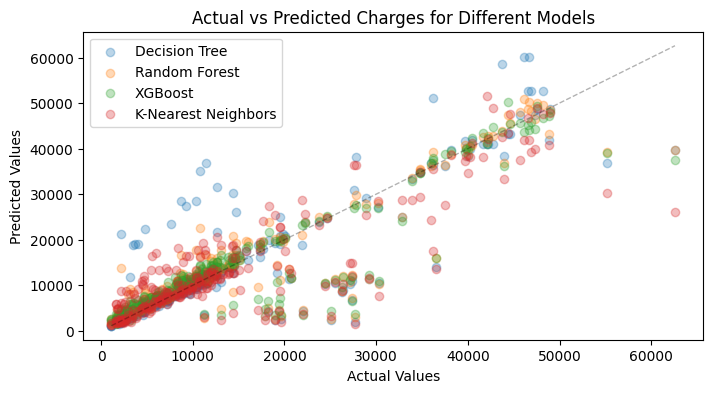

In [30]:
# Plot predictions vs actual values for all models
plt.figure(figsize=(8, 4))
plt.scatter(y_val, predictions["Decision Tree"], label="Decision Tree", alpha=0.3)
plt.scatter(y_val, predictions["Random Forest"], label="Random Forest", alpha=0.3)
plt.scatter(y_val, predictions["XGBoost"], label="XGBoost", alpha=0.3)
plt.scatter(y_val, predictions["K-Nearest Neighbors"], label="K-Nearest Neighbors", alpha=0.3)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], "k--", lw=1, alpha=0.3)
plt.title("Actual vs Predicted Charges for Different Models")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.legend()
plt.show()

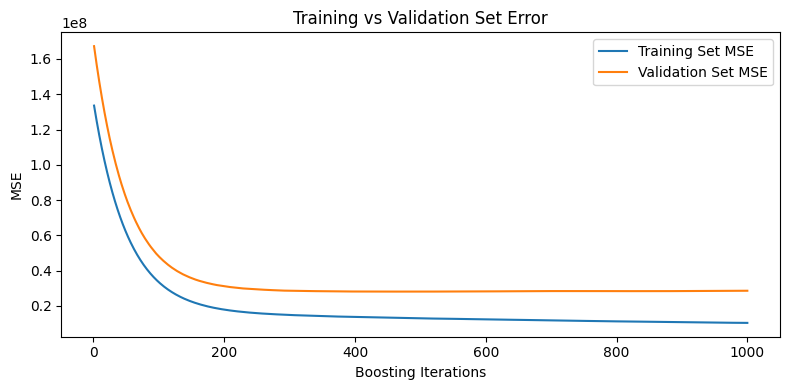

In [32]:
params = {
    "n_estimators": 1000,
    "max_depth": 4,
    "learning_rate": 0.01,
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "random_state": 42,
}

reg = XGBRegressor(**params)
reg.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)

results = reg.evals_result()

train_rmse = results["validation_0"]["rmse"]
val_rmse = results["validation_1"]["rmse"]

train_mse = np.array(train_rmse) ** 2
val_mse = np.array(val_rmse) ** 2

fig = plt.figure(figsize=(8, 4))
plt.title("Training vs Validation Set Error")
plt.plot(np.arange(params["n_estimators"]) + 1, train_mse, label="Training Set MSE")
plt.plot(np.arange(params["n_estimators"]) + 1, val_mse, label="Validation Set MSE")
plt.legend(loc="upper right")
plt.xlabel("Boosting Iterations")
plt.ylabel("MSE")
fig.tight_layout()
plt.show()

In [33]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

In [55]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 4, 5],
    "subsample": [0.8, 0.9, 1.0],
    "colsample_bytree": [0.8, 0.9, 1.0],
    "reg_alpha": [0, 0.01, 0.1],
    "reg_lambda": [1, 1.5, 2],
}

model = XGBRegressor(
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train_val, y_train_val)

# Grid search
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5)
grid_search.fit(X_train_val, y_train_val)

# საუკეთესო მოდელი
best_model = grid_search.best_estimator_
best_model

KeyboardInterrupt: 

In [ ]:
# Plot predictions vs actual values for all models
plt.figure(figsize=(8, 4))
plt.scatter(y_test, model.predict(X_test), label="XGBoost", alpha=0.5)
plt.scatter(y_test, best_model.predict(X_test), label="XGBoost tunning", alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=1, alpha=0.5)
plt.title("Actual vs Predicted Charges")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.legend()
plt.show()

### Breast Cancer Wisconsin (Diagnostic) Data Set

<img src="../../images/samples.png" alt="train_test" width=1000>

In [56]:
# მონაცემების ჩატვირთვა
data = load_breast_cancer()
feature_names = data.feature_names
X, y = pd.DataFrame(data.data, columns=feature_names), pd.Series(data.target)

df_cancer = X.copy()
df_cancer["diagnosis"] = y
df_cancer.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [57]:
# მონაცემთა გაყოფა სასწავლო (60%), სატესტო (20%), ვალიდაციის (20%) ნაწილებად
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)  # 0.25 * 0.8 = 0.2

In [58]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Nearest Neighbors": KNeighborsClassifier(n_neighbors=3),
    "Linear SVM": SVC(kernel="linear", C=0.025, random_state=42)
}

confusion_matrices = []
table_rows = []

# iterate over classifiers
for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_val)
    
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred, average="weighted")
    recall = recall_score(y_val, y_pred, average="weighted")
    f1 = f1_score(y_val, y_pred, average="weighted")
    table_rows.append([name, accuracy, precision, recall, f1])
    confusion_matrices.append(confusion_matrix(y_val, y_pred))

# Create a DataFrame from the table rows
results_df = pd.DataFrame(table_rows, columns=["Model", "accuracy", "precision", "recall", "F1"])
results_df = results_df.sort_values(by="F1", ascending=False).round(2)
results_df

,Model,accuracy,precision,recall,F1
4,Linear SVM,0.96,0.96,0.96,0.96
2,Gradient Boosting,0.96,0.96,0.96,0.96
1,Random Forest,0.95,0.95,0.95,0.95
3,Nearest Neighbors,0.94,0.94,0.94,0.94
0,Decision Tree,0.93,0.93,0.93,0.93


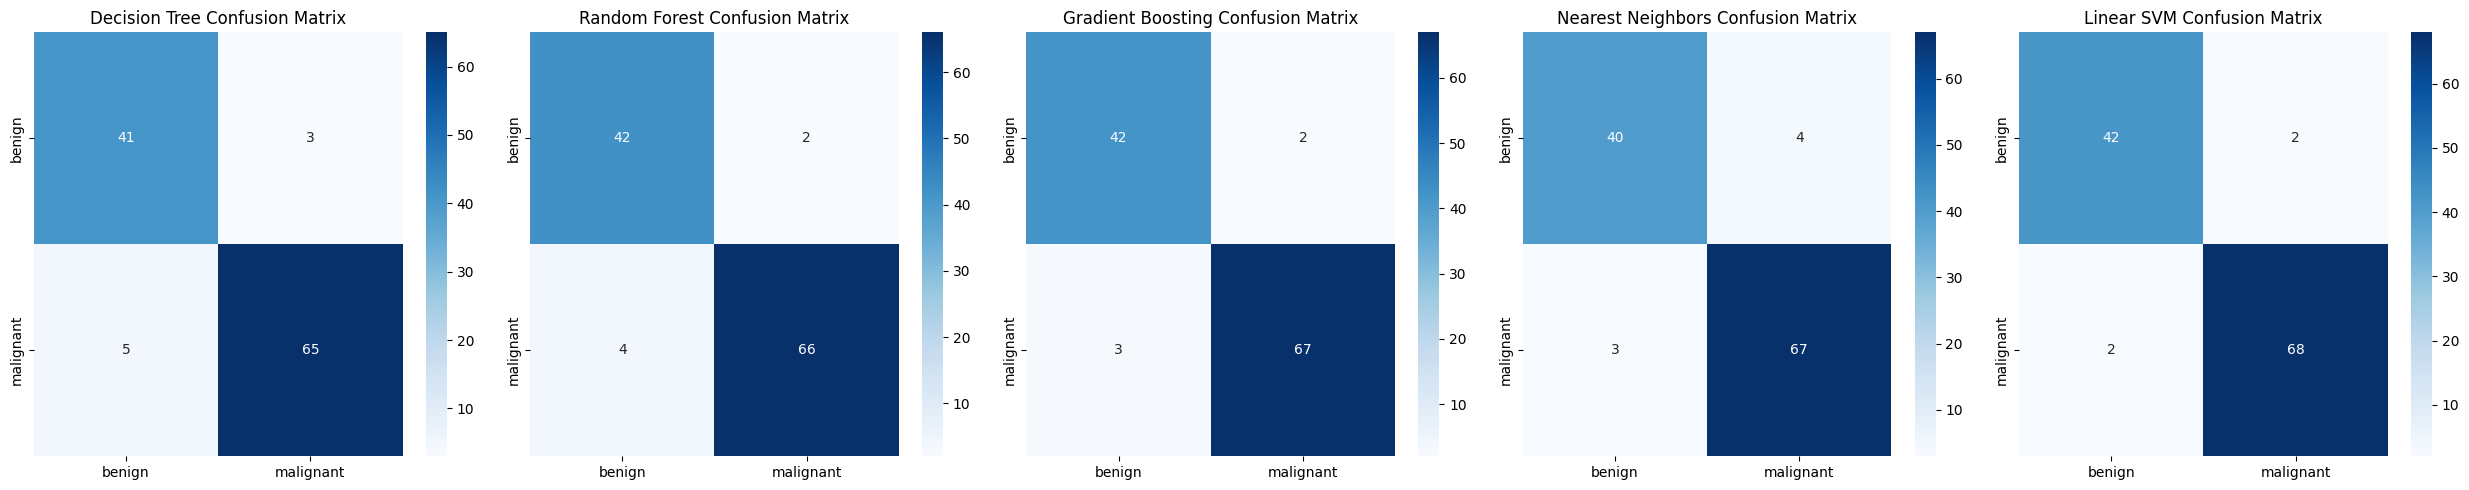

In [39]:
plt.figure(figsize=(25, 5))
for i, (name, confusion_matr) in enumerate(zip(models.keys(), confusion_matrices)):
    plt.subplot(1, 5, i+1)
    sns.heatmap(confusion_matr, annot=True, cmap="Blues", fmt="g", xticklabels=["benign", "malignant"], yticklabels=["benign", "malignant"])
    plt.title(f"{name} Confusion Matrix")
plt.tight_layout()
plt.show()

In [40]:
parameters = {
    "kernel":("linear", "rbf", "poly"), 
    "C":[0.001, 0.01, 0.1, 1, 10, 100], 
    "gamma":[0.001, 0.01, 0.1, 1, 10, 100]
}

svc = SVC()
clf = GridSearchCV(svc, parameters)
clf.fit(X_train, y_train)

best_estimator = clf.best_estimator_
print(best_estimator)

KeyboardInterrupt: 

In [ ]:
best_estimator.fit(X_train, y_train)
y_pred =  best_estimator.predict(X_test)

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrices[4], annot=True, cmap="Blues", fmt="g", xticklabels=["benign", "malignant"], yticklabels=["benign", "malignant"])
plt.title("SVM before hyperparameter tuning")
plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap="Blues", fmt="g", xticklabels=["benign", "malignant"], yticklabels=["benign", "malignant"])
plt.title("SVM after hyperparameter tuning")
plt.tight_layout()
plt.show()

| Model                  | Hyperparameter           | Description                                                   | Common Values                      | Task |
| ---------------------- | ------------------------ | ------------------------------------------------------------- | ---------------------------------- | ---- |
| **LinearRegression**   | `fit_intercept`          | Whether to calculate the intercept term                       | `True`, `False`                    | R    |
|                        | `normalize` (deprecated) | Whether to normalize input features                           | `True`, `False`                    | R    |
|                        | —                        | *→ No real tuning unless using Ridge/Lasso*                   |                                    |      |
| **LogisticRegression** | `C`                      | Inverse of regularization strength (lower = stronger penalty) | `0.001` to `1000` (log scale)      | C    |
|                        | `penalty`                | Type of regularization                                        | `'l2'`, `'l1'`, `'elasticnet'`     | C    |
|                        | `solver`                 | Optimization algorithm                                        | `'liblinear'`, `'saga'`, `'lbfgs'` | C    |
|                        | `max_iter`               | Max number of iterations                                      | `100` to `1000`                    | C    |
| **DecisionTree**       | `max_depth`              | Maximum depth of the tree                                     | `None`, `5`-`50`                   | R/C  |
|                        | `min_samples_split`      | Min samples to split a node                                   | `2`-`20`                           | R/C  |
|                        | `min_samples_leaf`       | Min samples per leaf node                                     | `1`-`10`                           | R/C  |
|                        | `max_features`           | Number of features to consider at each split                  | `'auto'`, `'sqrt'`, float \[0-1]   | R/C  |
| **RandomForest**       | `n_estimators`           | Number of trees in the forest                                 | `100`-`1000`                       | R/C  |
|                        | `max_depth`              | Max depth of each tree                                        | `None`, `5`-`50`                   | R/C  |
|                        | `min_samples_split`      | Min samples for node split                                    | `2`-`20`                           | R/C  |
|                        | `max_features`           | Number of features to sample per tree                         | `'auto'`, `'sqrt'`, float          | R/C  |
|                        | `bootstrap`              | Whether to use bootstrap sampling                             | `True`, `False`                    | R/C  |
| **GradientBoosting**   | `n_estimators`           | Number of boosting stages                                     | `100`-`1000`                       | R/C  |
|                        | `learning_rate`          | Shrinks contribution of each tree                             | `0.01`-`0.3`                       | R/C  |
|                        | `max_depth`              | Max depth of individual trees                                 | `3`-`10`                           | R/C  |
|                        | `subsample`              | Fraction of samples per tree                                  | `0.5`-`1.0`                        | R/C  |
|                        | `min_samples_split`      | Same as in trees                                              | `2`-`20`                           | R/C  |
| **KNeighbors**         | `n_neighbors`            | Number of neighbors                                           | `1`-`30`                           | R/C  |
|                        | `weights`                | Weight function                                               | `'uniform'`, `'distance'`          | R/C  |
|                        | `metric`                 | Distance metric                                               | `'minkowski'`, `'euclidean'`, etc. | R/C  |
|                        | `p`                      | Power parameter (1 = Manhattan, 2 = Euclidean)                | `1`, `2`                           | R/C  |
| **SVM**                | `C`                      | Regularization strength                                       | `0.001`-`1000`                     | R/C  |
|                        | `kernel`                 | Kernel type                                                   | `'linear'`, `'rbf'`, `'poly'`      | R/C  |
|                        | `gamma`                  | Kernel coefficient (for `rbf`, `poly`, `sigmoid`)             | `'scale'`, `'auto'`, float         | R/C  |
|                        | `degree`                 | Degree of the polynomial kernel                               | `2`-`5`                            | R/C  |


### Feature Selection
#### Feature Importance

In [103]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [104]:
xgb_params = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": 3,
    "random_state": 42,
    "eval_metric": "logloss"
}

initial_model = XGBClassifier(**xgb_params)
initial_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [106]:
initial_y_pred = initial_model.predict(X_test)

print("Initial model accuracy:")
print(accuracy_score(y_test, initial_y_pred))

print(classification_report(y_test, initial_y_pred))
print(confusion_matrix(y_test, initial_y_pred))

Initial model accuracy:
0.956140350877193
              precision    recall  f1-score   support

           0       0.97      0.90      0.94        42
           1       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

[[38  4]
 [ 1 71]]


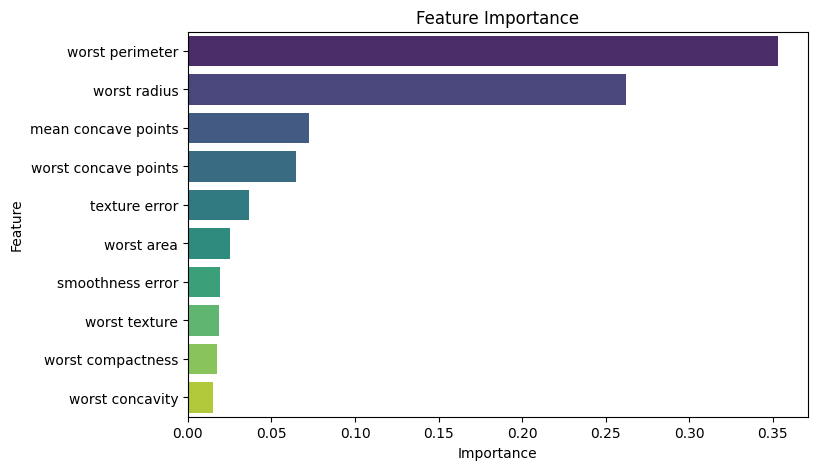

In [88]:
# Feature Importance
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": initial_model.feature_importances_})
importance_df = importance_df.sort_values(by="Importance", ascending=False)[:10]

# შედეგების ვიზუალიზაცია
plt.figure(figsize=(8, 5))
sns.barplot(x=importance_df["Importance"], y=importance_df["Feature"], palette="viridis")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance");

### SHAP - SHapley Additive exPlanations
SHAP Explainer ხსნის მოდელის გადაწყვეტილებას, აჩვენებს ყველაზე მნიშვნელოვან მახასიათებლებს, გვეხმარება ვუპასუხოთ: რომელი მახასიათებლები უბიძგებენ მოდელს დადებითი კლასისკენ?

SHAP Explainer-ის ტიპები:

Explainer | გამოიყენება | აღწერა
----------|----------| ----------
TreeExplainer | Decision trees (e.g. XGBoost, LightGBM, RandomForest, etc.) | ძალიან სწრაფი და ზუსტი
KernelExplainer | ნებისმიერი მოდელისთვის | ნელი, მაგრამ უნივერსალური
LinearExplainer | წრფივი მოდელებისთვის | ზუსტი და სწრაფი
DeepExplainer | TensorFlow / Keras ნეირონული ქსელებისთვის | მუშაობს deep learning-ზე
Explainer | ახალი API, ავტომატურად ირჩევს შესაბამის ტიპს | რეკომენდებულია

In [89]:
sample_ind = np.random.choice(X_train.index)

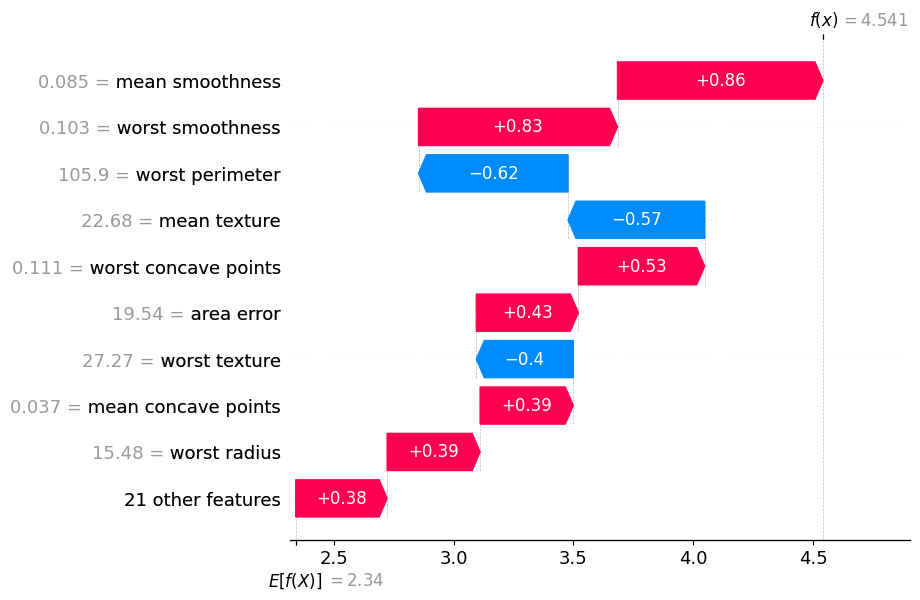

In [90]:
# SHAP Explainer
explainer = shap.Explainer(initial_model, X_train)
shap_values = explainer(X_train)

# Waterfall plot კონკრეტული მონაცემისთვის
shap.plots.waterfall(shap_values[sample_ind], max_display=10)

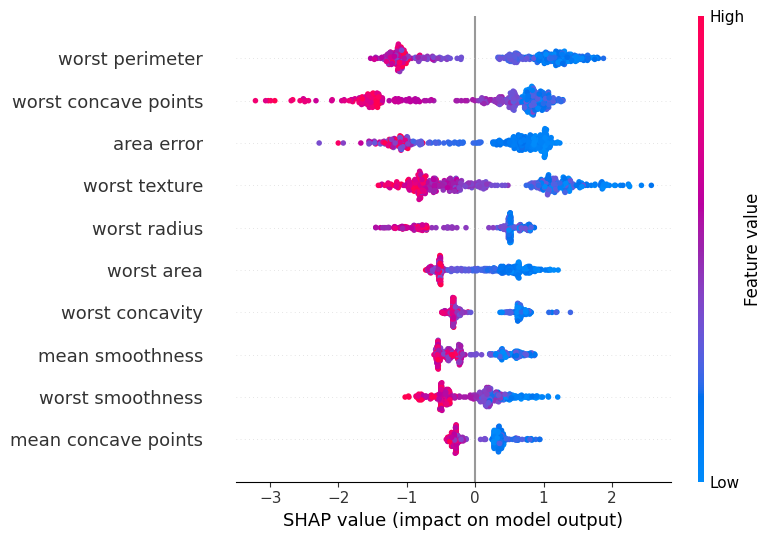

In [91]:
# SHAP Explainer (TreeExplainer უფრო სწრაფია decision tree-ზე)
explainer = shap.TreeExplainer(initial_model)
shap_values = explainer.shap_values(X_train)

# SHAP Summary Plot – მახასიათებლების მნიშვნელობა და ზეგავლენა
shap.summary_plot(shap_values, X_train, max_display=10)

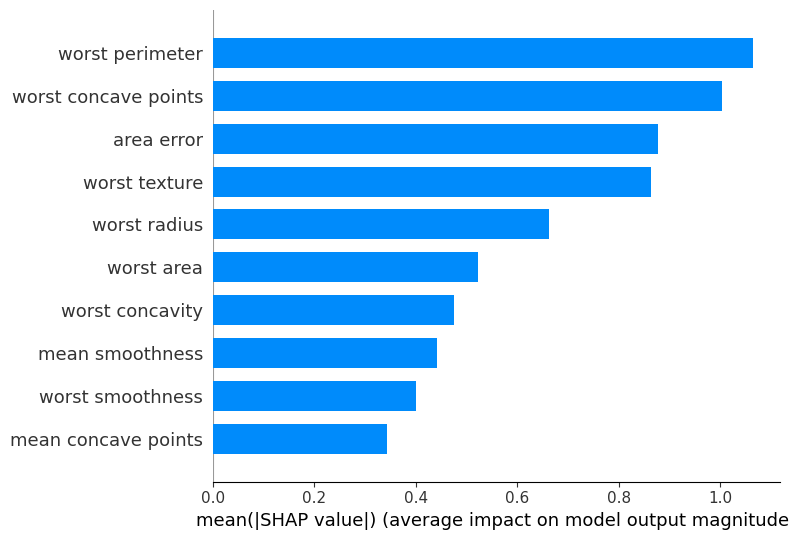

In [92]:
shap.summary_plot(shap_values, X_train, plot_type="bar", max_display=10)

In [93]:
# SelectKBest - სტატისტიკური ტესტების გამოყენებით ითვლის თითოეული მახასიათებელსა და სამიზნის (target) შორის დამოკიდებულებას.
selector = SelectKBest(score_func=f_classif, k=10)
X_new = selector.fit_transform(X, y)

# SelectKBest-ის შედეგი დავბეჭდოთ
selected_features = feature_names[selector.get_support()]
print("Selected Features:", selected_features.tolist())

Selected Features: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


In [94]:
# VarianceThreshold: Removes features with low variance.
selector = VarianceThreshold(threshold=1)
selector.fit(X)

mask = selector.get_support()
selected_features = np.array(feature_names)[mask]

print("Selected Features:", selected_features.tolist())

Selected Features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area']


In [95]:
# Recursive Feature Elimination - ეტაპობრივად შლის ნაკლებად მნიშვნელოვან მახასიათებლებს
rfe = RFE(estimator=initial_model, n_features_to_select=10)
X_rfe = rfe.fit_transform(X, y)

# დავბეჭდოთ 
selected_rfe = feature_names[rfe.support_]
print("Selected Features:", selected_rfe.tolist())

Selected Features: ['mean texture', 'mean area', 'mean concave points', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


| Feature               | Feature Importance | Shap Values | SelectKBest | VarianceThreshold | RFE |
|------------------------|---------------------|--------------|--------------|---------------------|-----|
| mean concave points    | ✓                  | ✓           | ✓           | ✗                  | ✓  |
| worst concave points   | ✓                  | ✓           | ✓           | ✗                  | ✓  |
| worst radius           | ✓                  | ✓           | ✓           | ✓                  | ✓  |
| worst perimeter        | ✓                  | ✓           | ✓           | ✓                  | ✓  |
| worst texture          | ✓                  | ✓           | ✗           | ✓                  | ✓  |
| worst area             | ✓                  | ✓           | ✓           | ✓                  | ✓  |
| mean texture           | ✓                  | ✓           | ✗           | ✓                  | ✓  |
| worst concavity        | ✓                  | ✓           | ✓           | ✗                  | ✓  |
| concavity error        | ✓                  | ✗           | ✗           | ✗                  | ✗  |
| area error             | ✓                  | ✓           | ✗           | ✓                  | ✓  |
| mean radius            | ✗                  | ✗           | ✓           | ✓                  | ✗  |
| mean perimeter         | ✗                  | ✗           | ✓           | ✓                  | ✗  |
| mean area              | ✗                  | ✗           | ✓           | ✓                  | ✗  |
| mean concavity         | ✗                  | ✗           | ✓           | ✗                  | ✗  |
| perimeter error        | ✗                  | ✗           | ✗           | ✓                  | ✗  |
| worst smoothness       | ✗                  | ✓           | ✗           | ✗                  | ✓  |

#### Feature Selection Pipeline

In [127]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

final_model = Pipeline([
    ("variance_threshold", VarianceThreshold(threshold=0.01)),
    ("rfecv", RFECV(
        estimator=initial_model,
        step=1,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        min_features_to_select=1
    )),
    ("classifier", XGBClassifier(**xgb_params))
])

final_model.fit(X_train, y_train)

final_y_pred = final_model.predict(X_test)

print("Final model accuracy:")
print(accuracy_score(y_test, final_y_pred))

print(classification_report(y_test, final_y_pred))
print(confusion_matrix(y_test, final_y_pred))

Final model accuracy:
0.956140350877193
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

[[39  3]
 [ 2 70]]


In [128]:
variance_selector = final_model.named_steps["variance_threshold"]
rfecv_selector = final_model.named_steps["rfecv"]

features_after_variance = X_train.columns[variance_selector.get_support()]
selected_features = features_after_variance[rfecv_selector.support_]

print("Initial number of features:", X_train.shape[1])
print("After VarianceThreshold:", len(features_after_variance))
print("After RFECV:", rfecv_selector.n_features_)

Initial number of features: 30
After VarianceThreshold: 14
After RFECV: 11


In [129]:
rfecv_ranking_df = pd.DataFrame({
    "Feature": features_after_variance,
    "Selected": rfecv_selector.support_,
    "Ranking": rfecv_selector.ranking_
}).sort_values("Ranking")

rfecv_ranking_df

,Feature,Selected,Ranking
1,mean texture,True,1
3,mean area,True,1
5,texture error,True,1
6,perimeter error,True,1
7,area error,True,1
8,worst radius,True,1
9,worst texture,True,1
10,worst perimeter,True,1
11,worst area,True,1
12,worst compactness,True,1
